(combine-studies)=
# Combine studies

Cohorts of one disease ask the same question of different donors, and each answers it
with its own samples, genes and names of cell types. To answer it with all of them,
align the cohorts' cubes in a {api}`CubeCollection`, analyse each cohort on its own,
and combine the results gene by gene by meta-analysis, with the forest plots and the
heterogeneity that metafor reports [@viechtbauer2010], or stack the cohorts into one
cube for a joint model.
[Meta-analysis](../statistics/meta_analysis.md) gives the statistics, and
[Replication across studies](replication_across_studies.ipynb) asks which changes
replicate.

The cohorts are simulated, so that the truth is known: the `simulated_cohorts`
dataset of the [Datasets](../reference/datasets.md) page, 164 donors in six
case-control cohorts of 12 to 60 donors, with the pseudobulk counts of four blood
cell types over 2,000 genes. The disease changes 100 genes of the monocytes in every
cohort, each case by an activity of its own, and fewer genes of the CD4 T cells and
B cells; each cohort also changes 10 monocyte genes of its own, in every case alike,
as a confounder of that cohort would. `python docs/datasets.py prepare simulated_cohorts`
writes a cube file for every cohort, and the code below opens them by name.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool.cube import CubeCollection
from cytepool.design import Design
from cytepool.differential_expression import limma_voom
from cytepool.io import read_cube
from cytepool.meta_analysis import (
    align_study_results,
    differential_expression_meta_analysis,
)
from cytepool.plotting import plot_forest, plot_significant_genes, plot_volcano

studies = [f"cohort_{i}" for i in range(1, 7)]
cubes = {study: read_cube(f"simulated_{study}.cube.zarr") for study in studies}
print(f"CytePool {cytepool.__version__}, numpy {np.__version__}")
for study, cube in cubes.items():
    cases = np.count_nonzero(cube.samples["condition"] == "case")
    genes = f"{cube.n_features:,} genes"
    if "measured" in cube.features:
        measured = np.count_nonzero(cube.features["measured"])
        genes += f" ({measured:,} measured)"
    print(f"{study}: {cube.n_samples} donors ({cases} cases), {genes}")
    print("    " + ", ".join(cube.groups["group_id"].tolist()))

CytePool 0.1.dev55+g941b81fb5, numpy 2.5.4
cohort_1: 60 donors (30 cases), 2,000 genes
    B cells, CD4 T cells, NK cells, CD14 monocytes
cohort_2: 32 donors (16 cases), 2,000 genes
    B, CD4, NK, CD14 Mono
cohort_3: 24 donors (12 cases), 1,800 genes
    B cell, CD4+ T cell, NK cell, CD14+ monocyte
cohort_4: 16 donors (8 cases), 2,000 genes
    B, CD4 naive, CD4 memory, NK, Mono CD14
cohort_5: 12 donors (6 cases), 2,000 genes (1,850 measured)
    Bcell, T_CD4, NK, Mono_CD14
cohort_6: 20 donors (10 cases), 2,000 genes
    B cells, CD4+ T cells, CD14+ monocytes


## Align the cohorts

The cubes cannot be compared as they are. Every cohort numbers its donors D01, D02,
..., so donor D01 of one cohort is not donor D01 of another. cohort_3's annotation
lacks 200 genes, and cohort_5's exporter wrote zeros for 150 genes it did not
measure, which its feature column `measured` marks: a zero there is not a count. And
every cohort names its cell types in its own words.

{api}`CubeCollection` aligns them. It names every sample `study::sample_id`, aligns
the genes by `feature_id` and records which cohort measured which
({api}`CubeCollection.measured`), and aligns the cell types by their Cell Ontology
ids [@diehl2016], which every cube's group table holds in `cell_ontology_id`:
CL:0000236 (B cell), CL:0000624 (CD4-positive, alpha-beta T cell), CL:0000623
(natural killer cell) and CL:0001054 (CD14-positive monocyte). cohort_4 annotated
its CD4 T cells more finely, as naive (CL:0000895) and memory (CL:0000897) cells,
which the ontology places under CL:0000624; `group_mapping` rolls them up to it, and
the collection merges the two, exactly, since a cube's layers are sums
([The cube and its additive layers](../statistics/cubes.md#several-studies)).

In [2]:
cd4_subsets = {"CD4 naive": "CL:0000624", "CD4 memory": "CL:0000624"}
collection = CubeCollection(cubes, group_mapping={"cohort_4": cd4_subsets})
print(collection)
ids = collection.samples["sample_id"]
print(f"  samples: {ids[0]}, {ids[1]}, ..., {ids[-1]}")
members = collection.group_members
cd4 = members["group_id"] == "CL:0000624"
print("\nCL:0000624 holds")
for study in collection.studies:
    names = members["study_group_id"][cd4 & (members["study"] == study)]
    print(f"  {study}: {', '.join(names)}")

CubeCollection of 6 studies: 164 samples, 4 groups, 2,000 features
  groups aligned by 'cell_ontology_id'
  cohort_1: 60 samples, 4 groups, 2,000 features measured
  cohort_2: 32 samples, 4 groups, 2,000 features measured
  cohort_3: 24 samples, 4 groups, 1,800 features measured
  cohort_4: 16 samples, 4 groups (1 merged), 2,000 features measured
  cohort_5: 12 samples, 4 groups, 1,850 features measured
  cohort_6: 20 samples, 3 groups, 2,000 features measured
  in every study: 3 groups, 1,650 features
  samples: cohort_1::D01, cohort_1::D02, ..., cohort_6::D20

CL:0000624 holds
  cohort_1: CD4 T cells
  cohort_2: CD4
  cohort_3: CD4+ T cell
  cohort_4: CD4 naive, CD4 memory
  cohort_5: T_CD4
  cohort_6: CD4+ T cells


## Analyse each cohort on its own

{api}`CubeCollection.aligned_cube` gives a cohort's cube on the collection's axes: its
cell types under their aligned ids, merged where several share one, the genes it
measured, and its own samples, so that a design built from its own sample table
applies. Each cohort is tested by {api}`limma_voom`, cases against controls, and its
results are keyed by the aligned cell types. {api}`plot_significant_genes` shows what
each cohort finds.

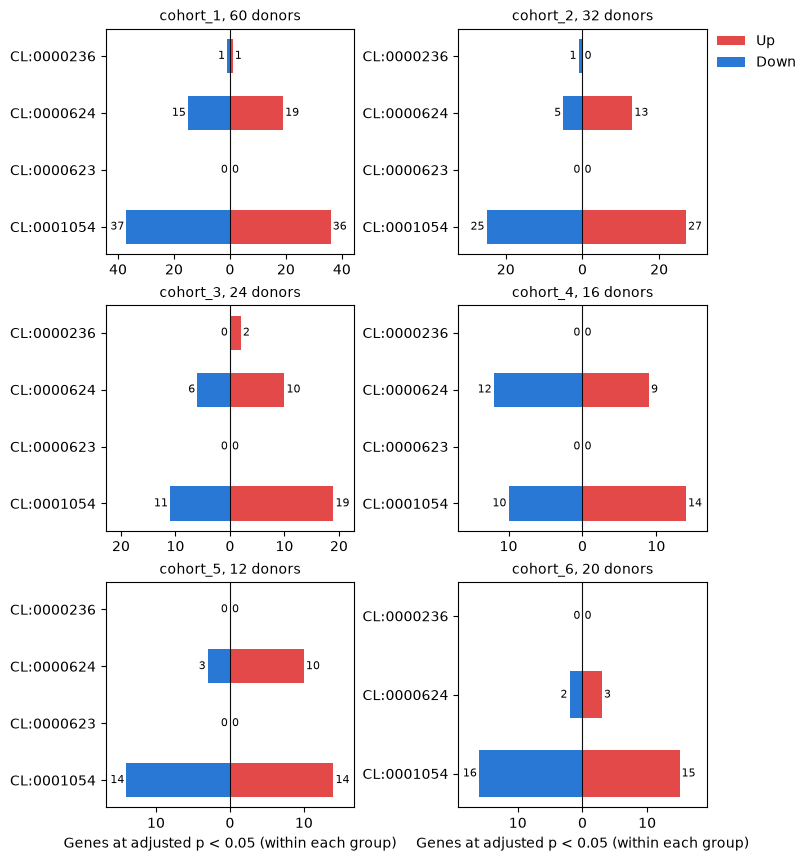

In [3]:
contrast = "case_vs_control"
results = {}
for study in collection.studies:
    cube = collection.aligned_cube(study)
    design = Design(
        cube.samples,
        "~ condition",
        levels={"condition": ["control", "case"]},
        contrasts={contrast: "conditioncase"},
    )
    results[study] = limma_voom(cube, design)

figure, axes = plt.subplots(3, 2, figsize=(8, 8.5), layout="constrained")
for ax, (study, result) in zip(axes.flat, results.items()):
    plot_significant_genes(result, ax=ax)
    ax.set_title(f"{study}, {cubes[study].n_samples} donors", fontsize=10)
    if ax is not axes.flat[1]:
        ax.get_legend().remove()
for ax in axes[:-1].flat:
    ax.set_xlabel("")
plt.show()

The larger cohorts find more: cohort_1, with 60 donors, finds 73 monocyte genes, and
the cohorts of 12 to 32 donors 24 to 52. None finds a gene of the NK cells, which the
disease does not change, and cohort_6 has no NK cells to test.

{api}`align_study_results` lines up the results of one cell type and contrast gene by
gene, with a row for every cohort and every gene of the collection, and says why a
cohort has no result for a gene: it did not measure the gene, or measured it and left
it out, as its expression filter does with genes too rarely detected. For the
monocytes:

In [4]:
monocytes = "CL:0001054"
aligned = align_study_results(collection, results, monocytes, contrast)
statuses = ("tested", "not_tested", "not_measured")
print(f"{'':<10}{'tested':>8}{'not tested':>12}{'not measured':>14}")
for study in collection.studies:
    status = aligned["status"][aligned["study"] == study]
    counts = [np.count_nonzero(status == kind) for kind in statuses]
    print(f"{study:<10}{counts[0]:>8,}{counts[1]:>12,}{counts[2]:>14,}")

            tested  not tested  not measured
cohort_1     1,973          27             0
cohort_2     1,942          58             0
cohort_3     1,753          47           200
cohort_4     1,960          40             0
cohort_5     1,554         296           150
cohort_6     1,971          29             0


cohort_3 did not measure 200 genes and cohort_5 150; their expression filters left out
47 and 296 more, cohort_5's the most, with the fewest donors and counts.

## Meta-analysis

{api}`differential_expression_meta_analysis` combines, for every cell type and gene,
the log2 fold changes of the cohorts that tested it, each with its standard error,
into one estimate. By default it fits the random-effects model, which lets the
cohorts' true effects vary around their mean by the between-study variance τ²
[@dersimonian1986], estimated by restricted maximum likelihood (REML) as metafor
estimates it by default, and tests the mean with a z-test. A gene that two cohorts or
more tested is analysed over those cohorts, so the genes that cohort_3 and cohort_5
did not measure are analysed over the other cohorts. {api}`plot_volcano` draws the
monocytes' table.

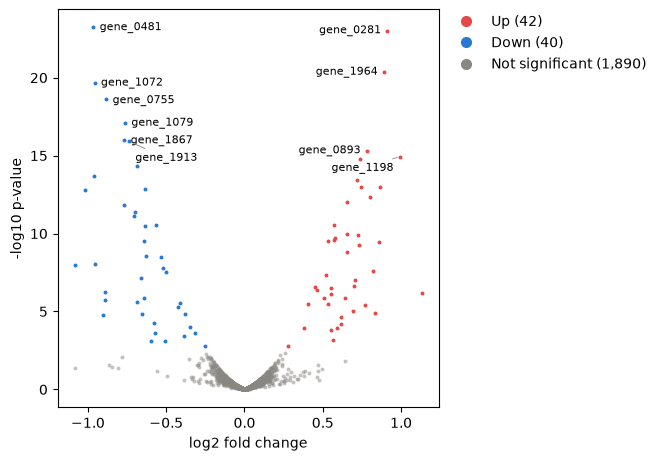

In [5]:
meta = differential_expression_meta_analysis(results)
table = meta.table(monocytes, contrast)
plot_volcano(table)
plt.show()

## One gene across the cohorts

{api}`plot_forest` draws one gene's log2 fold change in every cohort with its 95%
confidence interval, each square sized by the cohort's weight, and the pooled
estimate as a diamond, as metafor's `forest` does [@lewis2001]. The upper plot is the
monocyte gene the meta-analysis finds most clearly. The lower one is the gene that
cohort_1 finds most clearly among those the simulation changed in cohort_1 alone; the
fixed-effect model, which assumes one true effect for every cohort, is fitted too
(`method="fixed"`).

gene_1312, pooled log2 fold change [95% interval]:
  fixed effect: 0.50 [0.33, 0.66], adjusted p 9e-08
  random effects: 0.16 [-0.43, 0.74], adjusted p 1


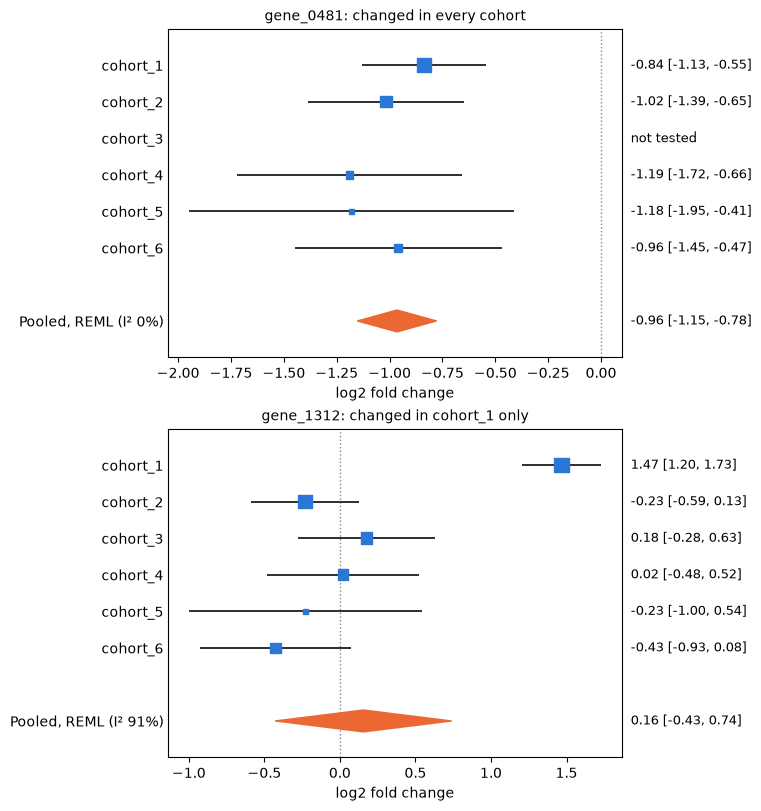

In [6]:
truth = np.load("simulated_cohorts_truth.npz")
genes = truth["feature_id"]
cell_type = list(truth["cell_ontology_ids"]).index(monocytes)
changed = truth["true_log2_fold_change"][:, cell_type] != 0  # cohorts x genes
everywhere = genes[changed.all(axis=0)]
one_cohort = genes[changed.sum(axis=0) == 1]
unchanged = genes[~changed.any(axis=0)]
truth_sets = (everywhere, one_cohort, unchanged)

strongest = table["feature_id"][np.argmin(table["p_value"])]
first = results["cohort_1"].table(monocytes, contrast)
cohort_1_only = genes[changed[0] & (changed.sum(axis=0) == 1)]
own = np.isin(first["feature_id"], cohort_1_only)
own_gene = first["feature_id"][own][np.argmin(first["p_value"][own])]
fixed = differential_expression_meta_analysis(results, method="fixed")
print(f"{own_gene}, pooled log2 fold change [95% interval]:")
for name, analysis in (("fixed effect", fixed), ("random effects", meta)):
    found = analysis.table(monocytes, contrast)
    i = np.flatnonzero(found["feature_id"] == own_gene)[0]
    change, p = found["log2_fold_change"][i], found["adjusted_p_value"][i]
    low, high = found["ci_lower"][i], found["ci_upper"][i]
    print(f"  {name}: {change:.2f} [{low:.2f}, {high:.2f}], adjusted p {p:.2g}")

figure, axes = plt.subplots(2, 1, figsize=(7.5, 8), layout="constrained")
for ax, gene in zip(axes, (strongest, own_gene)):
    plot_forest(meta, results, gene, group=monocytes, contrast=contrast, ax=ax)
axes[0].set_title(f"{strongest}: changed in every cohort", fontsize=10)
axes[1].set_title(f"{own_gene}: changed in cohort_1 only", fontsize=10)
plt.show()

In the upper plot the cohorts agree: every estimate lies below zero, I² is 0%, and
the pooled log2 fold change, -0.96, has a narrow interval; cohort_3 did not measure
the gene and keeps its row, marked not tested. In the lower one, cohort_1 changes the
gene by 1.47 and the other cohorts' estimates lie around zero. Cochran's Q
[@cochran1954] finds the cohorts far more different than their standard errors allow,
and I² [@higgins2002] puts 91% of the variation down to heterogeneity: the
random-effects model widens the pooled interval to [-0.43, 0.74] and does not find the
gene. The fixed-effect model gives cohort_1, the most precise cohort, the largest
weight and finds it, with an adjusted p-value of 9e-08.

## Stack the cohorts into one cube

{api}`CubeCollection.stack` puts the cohorts into one cube for a joint model, with
every cohort's samples and the cohort as a column of the sample table. A cube holds
no missing values, so the stacked cube keeps the genes that every cohort measured and
the cell types that every cohort has; each cohort keeps its own counts and library
sizes. {api}`CubeCollection.select` chooses the cohorts, cell types and genes of an
analysis, such as the cohorts that measured every gene. The design
`~ study + condition` gives every gene a baseline in each cohort and one difference
between cases and controls, shared by all.

In [7]:
stacked = collection.stack()
print(stacked)
complete = collection.select(studies=collection.measured.all(axis=1))
n_genes = complete.stack().n_features
print(f"  {complete.n_studies} cohorts measured every gene: {n_genes:,} genes")
design = Design(
    stacked.samples,
    "~ study + condition",
    levels={"condition": ["control", "case"]},
    contrasts={contrast: "conditioncase"},
)
joint = limma_voom(stacked, design)

Cube with 164 samples x 3 groups x 1,650 features
  layers: counts (int64)
  filled: 492 of 492 sample x group entries have cells (100.0%)
  samples: sample_id, study, condition
  groups: group_id, cell_ontology_id
  features: feature_id
  4 cohorts measured every gene: 2,000 genes


## The approaches against the truth

The simulation knows which genes each approach should find. The monocyte genes found
at a false discovery rate of 5% by cohort_1 alone, by the meta-analyses and by the
joint model, split by what the simulation did to them:

genes changed everywhere: 100, in the stack: 82


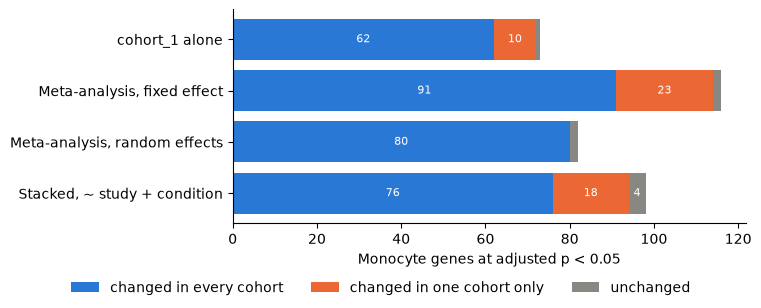

In [8]:
def by_truth(table):
    called = table["feature_id"][table["adjusted_p_value"] < 0.05]
    return [np.isin(called, kind).sum() for kind in truth_sets]


approaches = {
    "cohort_1 alone": first,
    "Meta-analysis, fixed effect": fixed.table(monocytes, contrast),
    "Meta-analysis, random effects": table,
    "Stacked, ~ study + condition": joint.table(monocytes, contrast),
}
counts = np.array([by_truth(found) for found in approaches.values()])
in_stack = np.isin(everywhere, stacked.features["feature_id"]).sum()
print(f"genes changed everywhere: {everywhere.size}, in the stack: {in_stack}")

labels = ("changed in every cohort", "changed in one cohort only", "unchanged")
colors = ("#2a78d6", "#eb6834", "#898781")
figure, ax = plt.subplots(figsize=(7.5, 3), layout="constrained")
names, left = list(approaches), np.zeros(len(approaches))
for column, (label, color) in enumerate(zip(labels, colors)):
    values = counts[:, column]
    bars = ax.barh(names, values, left=left, color=color, label=label)
    shown = [f"{n}" if n >= 4 else "" for n in values]
    ax.bar_label(bars, shown, label_type="center", color="white", fontsize=8)
    left += values
ax.invert_yaxis()
ax.set_xlabel("Monocyte genes at adjusted p < 0.05")
ax.spines[["top", "right"]].set_visible(False)
figure.legend(loc="outside lower center", ncols=3, frameon=False)
plt.show()

cohort_1 alone finds 62 of the 100 genes that the disease changes in every cohort. The
fixed-effect meta-analysis finds the most of them, 91, and 23 genes of single cohorts
with them. The random-effects meta-analysis finds 80 and none of a single cohort: a
change in one cohort alone makes the cohorts disagree, which raises τ² and widens the
interval. The joint model assumes one change for every cohort, as the fixed effect
does, and finds 76 and 18; it tests only the genes that every cohort measured, which
hold 82 of the 100.

## Choices

- **Meta-analysis or a joint model.** A meta-analysis needs only each cohort's
  results, keeps the genes some cohorts did not measure, lets each cohort keep its own
  design, normalization and variances, and measures how far the cohorts disagree. A
  joint model of the stacked cohorts suits cohorts made alike, with one protocol and
  platform, that are too small to estimate their variances alone; it estimates one
  difference for every cohort, so a change in one cohort enters the estimate for all.
- **Fixed or random effects.** The fixed-effect model (`method="fixed"`) answers for
  the cohorts at hand and assumes they estimate one effect; the random-effects model,
  the default, allows the effect to vary between cohorts. τ² can also be estimated by
  DerSimonian and Laird's method (`"dl"`) or Paule and Mandel's (`"pm"`), and
  `test="knapp_hartung"` gives the t-tests that metafor's documentation recommends for
  few studies ([Meta-analysis](../statistics/meta_analysis.md#tests-and-heterogeneity)).
- **Genes that some cohorts did not test.** `min_studies`, two by default, sets how
  many cohorts must test a gene; {api}`align_study_results` says whether a cohort did
  not measure a gene or left it out.
- **Cell types and ids.** Cell types are aligned by `cell_ontology_id` when every
  cohort has it, by `group_id` otherwise, or by another column (`align_groups_by`);
  `group_mapping` names the aligned id of any group, or None to leave it out. Columns
  of ids other than `sample_id`, such as donors with several samples, are kept apart
  by cohort with `within_study`.